# E2: ¿se ve H1 en los datos?

**H1.** En una misma persona, el acoplamiento entre el ritmo cardíaco (RR) y la respiración derivada del ECG (EDR) se corre de la banda respiratoria a la banda lenta del ciclo de apnea durante la apnea. Por lo tanto, **CR = coherencia lenta / coherencia respiratoria es mayor en los minutos con apnea** que en los minutos sin apnea.

**Diseño (fijado antes de correr).** Es una prueba de hipótesis, así que la configuración no se elige con estos datos.
- **Prueba principal**, dos configuraciones con el mismo peso, corregidas por Holm. Ventana de 512 s (8,5 min; 1024 muestras a 2 Hz, 3 segmentos de Welch), CR como cociente:
  - **CPC publicado** (Thomas et al., 2005): bandas 0,01–0,1 Hz y 0,1–0,4 Hz.
  - **Esquema v2:** bandas 0,01–0,15 Hz y 0,15–0,4 Hz.
- **Datos:** los registros A/B de desarrollo (35 registros, 14 sujetos). Test no se usa.
- **Por registro:** mediana de CR en los minutos con apnea menos mediana en los minutos sin apnea. Se excluyen los minutos con más del 20 % de RR corregidos, y un registro entra si le quedan al menos 5 minutos de cada clase. **Por sujeto:** promedio de sus registros.
- **Test:** Wilcoxon de rangos con signo, dos colas, sobre una diferencia por sujeto. Tamaño del efecto: correlación rango-biserial; IC 95 % de la mediana por bootstrap de sujetos.
- **Regla:** H1 se sostiene si al menos una de las dos configuraciones da p de Holm < 0,05 con diferencia positiva, y ninguna da un resultado significativo en la dirección contraria.
- **Controles** (no cambian la decisión): mecanismo (la coherencia lenta sube y la respiratoria baja), sin la exclusión por calidad, robustez en una grilla de ventanas, bandas y formas de CR (Holm sobre toda la grilla), y la misma prueba con la respiración real en los registros que la tienen.
- **Mapas nocturnos**, elegidos por regla: el registro A con respiración más cercano a 50 % de apnea (a03) y el registro C con respiración con más minutos (c02).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RESULTS_DIR, SPLIT_CSV
from src.data import load_apnea_labels, load_respiration
from src.features.build import minute_coupling, record_minute_table, record_series
from src.features.coupling import coherence_spectrum, downsample
from src.stats.tests import holm, paired_subject_test

FIG = RESULTS_DIR / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"

split = pd.read_csv(SPLIT_CSV).set_index("record")
dev = split[split.set == "dev"]
AB = list(dev[dev.category.isin(["A", "B"])].index)
MAPAS = ["a03", "c02"]
RESP_AB = ["a01", "a02", "a03", "a04", "b01"]
assert set(MAPAS + RESP_AB) <= set(dev.index)               # solo desarrollo

BANDAS = {"cpc_lenta": (0.01, 0.1), "cpc_resp": (0.1, 0.4),
          "v2_lenta": (0.01, 0.15), "v2_resp": (0.15, 0.4), "apnea_lenta": (0.01, 0.05)}
CONFIGS = {"CPC publicado": ("cpc_lenta", "cpc_resp"),
           "esquema v2": ("v2_lenta", "v2_resp"),
           "banda de apnea": ("apnea_lenta", "v2_resp")}
VENTANAS = {"8,5 min": 512, "5 min": 300, "3 min": 180}
print(f"{len(AB)} registros A/B de {dev.loc[AB, 'subject'].nunique()} sujetos")

35 registros A/B de 14 sujetos


In [2]:
series, tablas = {}, []
for rec in AB + ["c02"]:
    s = record_series(rec)
    series[rec] = s
    for nombre, w in VENTANAS.items():
        tablas.append(record_minute_table(rec, w, BANDAS, series=s).assign(ventana=nombre))
tab = pd.concat(tablas, ignore_index=True)
tab["subject"] = tab.record.map(split.subject)
cal = tab[tab.ventana == "8,5 min"]
print(f"minutos con ventana completa (8,5 min): {len(cal)} | sin etiqueta: {(cal.label < 0).sum()} | "
      f"con más de 20 % de RR corregidos: {(cal.corrected > 0.2).sum()} ({100 * (cal.corrected > 0.2).mean():.1f} %)")

minutos con ventana completa (8,5 min): 17826 | sin etiqueta: 0 | con más de 20 % de RR corregidos: 411 (2.3 %)


In [3]:
FORMAS = {
    "cociente":     lambda t, lo, hi: t[f"coh_{lo}"] / t[f"coh_{hi}"],
    "log-cociente": lambda t, lo, hi: np.log(t[f"coh_{lo}"] / t[f"coh_{hi}"]),
    "diferencia":   lambda t, lo, hi: t[f"coh_{lo}"] - t[f"coh_{hi}"],
    "producto":     lambda t, lo, hi: (t[f"coh_{lo}"] * t[f"xp_{lo}"]) / (t[f"coh_{hi}"] * t[f"xp_{hi}"]),
}

def por_sujeto(t, valores, max_corr=0.2, min_min=5):
    # Diferencia (mediana con apnea - mediana sin apnea) por registro, promediada por sujeto.
    d = t.assign(v=np.asarray(valores, dtype=float))
    d = d[(d.label >= 0) & np.isfinite(d.v)]
    if max_corr is not None:
        d = d[d.corrected <= max_corr]
    filas = []
    for rec, g in d.groupby("record"):
        a, n = g.v[g.label == 1], g.v[g.label == 0]
        if len(a) >= min_min and len(n) >= min_min:
            filas.append({"record": rec, "subject": g.subject.iloc[0], "delta": a.median() - n.median(),
                          "min. apnea": len(a), "min. normal": len(n)})
    r = pd.DataFrame(filas)
    return r.groupby("subject").delta.mean(), r

def probar(t, configs, forma="cociente", ventana="8,5 min", max_corr=0.2):
    filas = []
    tv = t[t.ventana == ventana]
    for nombre in configs:
        lo, hi = CONFIGS[nombre]
        dif, _ = por_sujeto(tv, FORMAS[forma](tv, lo, hi), max_corr)
        r = paired_subject_test(dif.to_numpy())
        filas.append({"configuración": nombre, "sujetos": r["n"], "positivos": r["positivos"],
                      "mediana Δ": r["mediana"], "IC 95 % mediana": "{:.3f} a {:.3f}".format(*r["ic_mediana"]),
                      "r rango-biserial": r["r_rb"], "p": r["p"]})
    out = pd.DataFrame(filas).set_index("configuración")
    out["p (Holm)"] = holm(out.p)
    return out

## Prueba principal

In [4]:
principal = probar(tab, ["CPC publicado", "esquema v2"])
sostiene = ((principal["p (Holm)"] < 0.05) & (principal["mediana Δ"] > 0)).any()
contraria = ((principal["p (Holm)"] < 0.05) & (principal["mediana Δ"] < 0)).any()
print("H1 SE SOSTIENE" if sostiene and not contraria else "H1 NO SE SOSTIENE con la regla fijada")
principal.round(4)

H1 SE SOSTIENE


,sujetos,positivos,mediana Δ,IC 95 % mediana,r rango-biserial,p,p (Holm)
configuración,,,,,,,
CPC publicado,14,11,0.1339,0.021 a 0.217,0.8095,0.0052,0.0105
esquema v2,14,10,0.0771,-0.012 a 0.141,0.6571,0.0295,0.0295


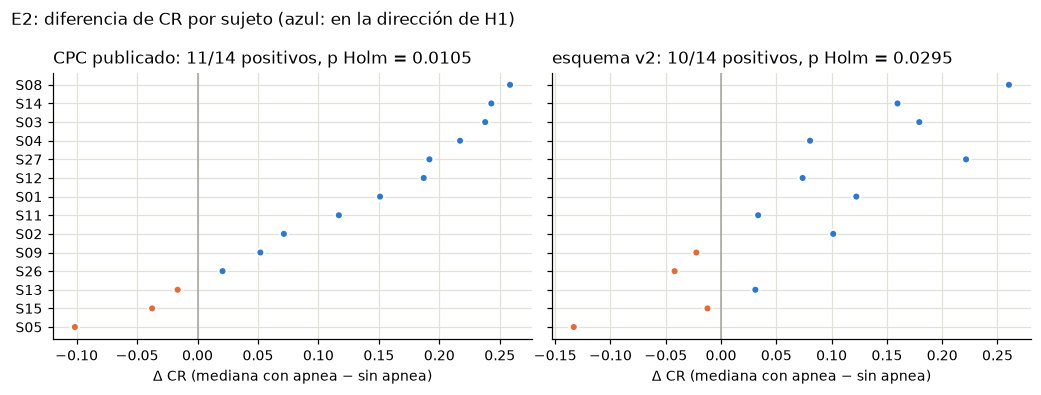

In [5]:
tv = tab[tab.ventana == "8,5 min"]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
orden = None
for ax, nombre in zip(axes, ["CPC publicado", "esquema v2"]):
    lo, hi = CONFIGS[nombre]
    dif, _ = por_sujeto(tv, FORMAS["cociente"](tv, lo, hi))
    orden = dif.sort_values().index if orden is None else orden
    dif = dif.reindex(orden)
    ax.axvline(0, color=GRIS, lw=1)
    ax.scatter(dif, range(len(dif)), s=30, color=[AZUL if v > 0 else NARANJA for v in dif],
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.set_yticks(range(len(dif)), dif.index)
    ax.set_xlabel("Δ CR (mediana con apnea − sin apnea)")
    p = principal.loc[nombre]
    ax.set_title(f"{nombre}: {p.positivos}/{p.sujetos} positivos, p Holm = {p['p (Holm)']:.3g}", loc="left")
fig.suptitle("E2: diferencia de CR por sujeto (azul: en la dirección de H1)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "E2_diferencias_por_sujeto.png")

## Mecanismo: ¿por qué cambia CR?

H1 dice que CR sube porque la coherencia lenta **sube** y la respiratoria **baja**. Se prueba cada una por separado (Holm sobre las 4 pruebas).

In [6]:
filas = []
for nombre in ["CPC publicado", "esquema v2"]:
    for banda, esperado in ((CONFIGS[nombre][0], "sube"), (CONFIGS[nombre][1], "baja")):
        dif, _ = por_sujeto(tv, tv[f"coh_{banda}"])
        r = paired_subject_test(dif.to_numpy())
        filas.append({"configuración": nombre, "banda": f"{BANDAS[banda][0]}–{BANDAS[banda][1]} Hz",
                      "esperado": esperado, "positivos": f"{r['positivos']}/{r['n']}",
                      "mediana Δ coherencia": r["mediana"], "r rango-biserial": r["r_rb"], "p": r["p"]})
mec = pd.DataFrame(filas)
mec["p (Holm)"] = holm(mec.p)
mec.round(4)

,configuración,banda,esperado,positivos,mediana Δ coherencia,r rango-biserial,p,p (Holm)
0,CPC publicado,0.01–0.1 Hz,sube,11/14,0.0383,0.7905,0.0067,0.0269
1,CPC publicado,0.1–0.4 Hz,baja,8/14,0.0136,-0.1619,0.6257,1.0000
2,esquema v2,0.01–0.15 Hz,sube,12/14,0.0232,0.7524,0.0107,0.0322
3,esquema v2,0.15–0.4 Hz,baja,8/14,0.0118,-0.1238,0.7148,1.0000


## Controles

### Sin excluir minutos por calidad del RR

In [7]:
probar(tab, ["CPC publicado", "esquema v2"], max_corr=None).round(4)

,sujetos,positivos,mediana Δ,IC 95 % mediana,r rango-biserial,p,p (Holm)
configuración,,,,,,,
CPC publicado,14,11,0.1337,0.021 a 0.213,0.8095,0.0052,0.0105
esquema v2,14,10,0.0721,-0.012 a 0.140,0.6571,0.0295,0.0295


### Robustez: toda la grilla de ventanas, bandas y formas de CR

36 pruebas (3 ventanas × 3 pares de bandas × 4 formas), con Holm sobre las 36. No se usa para elegir nada: solo muestra si el resultado depende de la configuración.

In [8]:
filas = []
for v in VENTANAS:
    for forma in FORMAS:
        r = probar(tab, list(CONFIGS), forma=forma, ventana=v)
        filas += [{"ventana": v, "forma": forma, "bandas": c, **r.loc[c, ["sujetos", "positivos", "r rango-biserial", "p"]].to_dict()}
                  for c in CONFIGS]
grilla = pd.DataFrame(filas)
grilla["p (Holm)"] = holm(grilla.p)
grilla["significativa"] = (grilla["p (Holm)"] < 0.05)
print(f"significativas tras Holm: {grilla.significativa.sum()} de {len(grilla)} | "
      f"en la dirección de H1: {(grilla.significativa & (grilla['r rango-biserial'] > 0)).sum()} | "
      f"en la contraria: {(grilla.significativa & (grilla['r rango-biserial'] < 0)).sum()}")
grilla.pivot_table(index=["ventana", "forma"], columns="bandas", values="r rango-biserial").round(2)

significativas tras Holm: 13 de 36 | en la dirección de H1: 13 | en la contraria: 0


bandas                CPC publicado  banda de apnea  esquema v2
ventana forma                                                  
3 min   cociente               0.83            0.87        0.64
        diferencia             0.83            0.89        0.60
        log-cociente           0.83            0.85        0.62
        producto               1.00            1.00        1.00
5 min   cociente               0.81            0.87        0.71
        diferencia             0.79            0.85        0.70
        log-cociente           0.79            0.85        0.71
        producto               1.00            1.00        1.00
8,5 min cociente               0.81            0.92        0.66
        diferencia             0.83            0.90        0.64
        log-cociente           0.79            0.89        0.66
        producto               1.00            1.00        1.00

### Con la respiración real en lugar del EDR

En los registros con respiración real y apnea, se repite el cálculo usando la respiración medida (promedio de la coherencia con los tres canales). Si el desplazamiento aparece igual, viene de la fisiología y no de un defecto del EDR. Son pocos registros: es descriptivo.

In [9]:
filas = []
for rec in RESP_AB:
    s = series[rec]
    resp, fr = load_respiration(rec)
    idx = np.rint(s["t"] * s["fs"]).astype(int)
    base = tv[tv.record == rec][["minute", "label", "corrected", "subject", "record"]]
    canales = []
    for c in ("Resp C", "Resp A", "Resp N"):
        r2 = downsample(resp[c], fr, s["fs"])
        y = np.full(len(idx), np.nan)
        ok = idx < len(r2)
        y[ok] = r2[idx[ok]]
        canales.append(minute_coupling(s["t"], s["rr"], y, s["fs"], len(load_apnea_labels(rec)), 512, BANDAS))
    real = pd.concat(canales).groupby("minute").mean().reset_index().merge(base, on="minute")
    edr = tv[tv.record == rec]
    fila = {"registro": rec}
    for nombre in ["CPC publicado", "esquema v2"]:
        lo, hi = CONFIGS[nombre]
        _, d_edr = por_sujeto(edr, FORMAS["cociente"](edr, lo, hi))
        _, d_real = por_sujeto(real, FORMAS["cociente"](real, lo, hi))
        fila[f"Δ CR con EDR ({nombre})"] = d_edr.delta.iloc[0] if len(d_edr) else np.nan
        fila[f"Δ CR con respiración real ({nombre})"] = d_real.delta.iloc[0] if len(d_real) else np.nan
    filas.append(fila)
fisio = pd.DataFrame(filas).set_index("registro")
fisio.round(3)

,Δ CR con EDR (CPC publicado),Δ CR con respiración real (CPC publicado),Δ CR con EDR (esquema v2),Δ CR con respiración real (esquema v2)
registro,,,,
a01,0.143,0.414,0.145,0.262
a02,0.145,0.276,0.120,0.242
a03,0.275,0.293,0.211,0.146
a04,0.230,0.426,0.062,0.298
b01,0.028,0.046,0.082,0.045


## Mapas nocturnos

Coherencia en cada frecuencia (eje vertical) a lo largo de la noche (eje horizontal), con ventanas de 8,5 min. Arriba de cada mapa, los minutos con apnea anotados. Las líneas punteadas marcan 0,1 y 0,15 Hz.

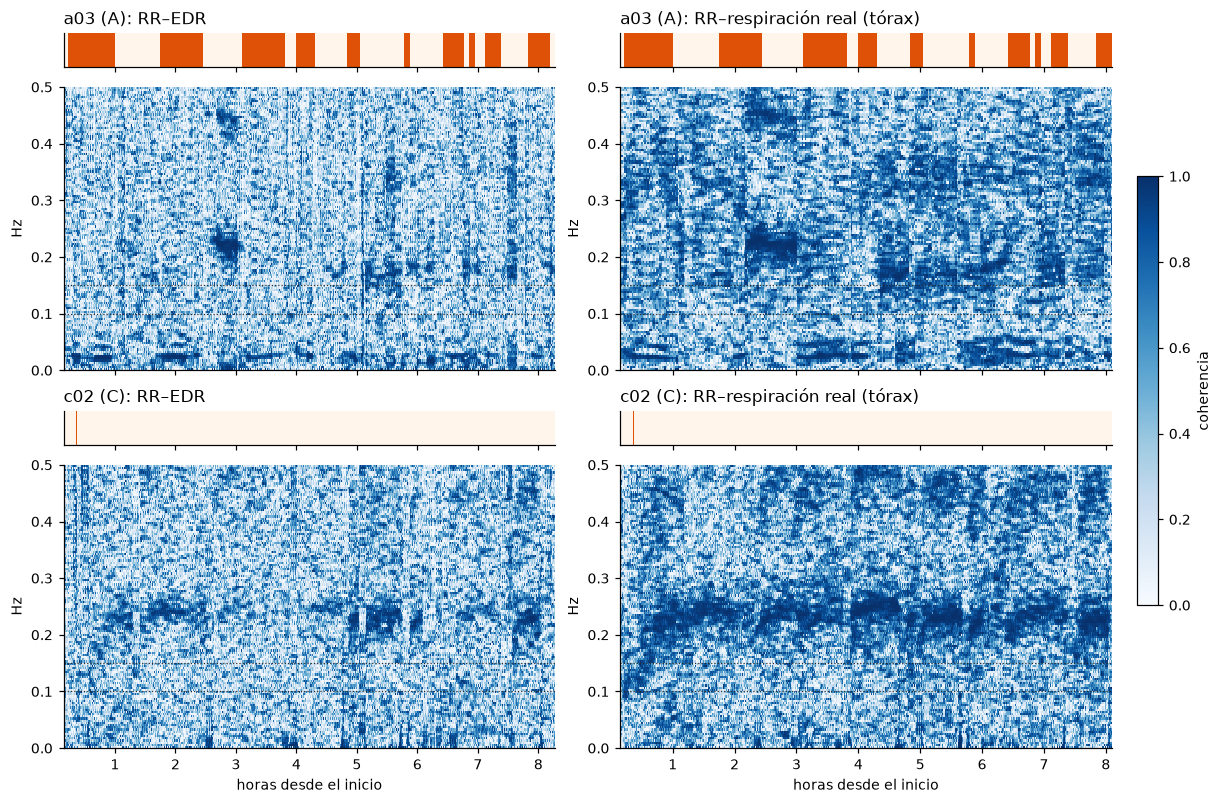

In [10]:
def mapa(t, x, y, fs, n_min, width_s=512):
    n = int(width_s * fs)
    filas, minutos = [], []
    for m in range(n_min):
        i = int(round((60 * m + 30 - width_s / 2 - t[0]) * fs))
        if i < 0 or i + n > len(t):
            continue
        xw, yw = x[i:i + n], y[i:i + n]
        if np.isfinite(xw).all() and np.isfinite(yw).all():
            f, c, _ = coherence_spectrum(xw, yw, fs, n // 2)
            filas.append(c); minutos.append(m)
    return np.array(minutos), f, np.array(filas)

fig, axes = plt.subplots(4, 2, figsize=(11, 7.2), sharex="col", layout="constrained",
                         gridspec_kw={"height_ratios": [0.12, 1, 0.12, 1]})
for fila, rec in enumerate(MAPAS):
    s = series[rec]
    lab = load_apnea_labels(rec)
    resp, fr = load_respiration(rec)
    idx = np.rint(s["t"] * s["fs"]).astype(int)
    r2 = downsample(resp["Resp C"], fr, s["fs"])
    y = np.full(len(idx), np.nan); ok = idx < len(r2); y[ok] = r2[idx[ok]]
    for col, (nombre, senal) in enumerate((("RR–EDR", s["edr"]), ("RR–respiración real (tórax)", y))):
        m, f, C = mapa(s["t"], s["rr"], senal, s["fs"], len(lab))
        sel = f <= 0.5
        ax_lab, ax = axes[2 * fila, col], axes[2 * fila + 1, col]
        ax_lab.imshow((lab == 1)[None, :], aspect="auto", cmap="Oranges", vmin=0, vmax=1.4,
                      extent=[0, len(lab) / 60, 0, 1], interpolation="nearest")
        ax_lab.set_yticks([]); ax_lab.grid(False)
        ax_lab.set_title(f"{rec} ({split.loc[rec, 'category']}): {nombre}", loc="left")
        im = ax.imshow(C[:, sel].T, origin="lower", aspect="auto", cmap="Blues", vmin=0, vmax=1,
                       extent=[m[0] / 60, (m[-1] + 1) / 60, f[sel][0], f[sel][-1]], interpolation="nearest")
        for fb in (0.1, 0.15):
            ax.axhline(fb, color=TINTA, lw=0.8, ls=":")
        ax.grid(False); ax.set_ylabel("Hz")
for ax in axes[-1]:
    ax.set_xlabel("horas desde el inicio")
fig.colorbar(im, ax=axes[:, 1].tolist(), shrink=0.6, label="coherencia")
fig.savefig(FIG / "E2_mapas_a03_c02.png", bbox_inches="tight")

## Decisión

- **H1 se sostiene con la regla fijada.** Con el CPC publicado, 11 de 14 sujetos van en la dirección esperada (rango-biserial 0,81; p = 0,005; p de Holm = 0,011). Con las bandas del esquema v2 el efecto es más débil: 10 de 14, rango-biserial 0,66, p de Holm = 0,03, y el IC de la mediana incluye 0.
- **El mecanismo no es el que proponía H1.** La coherencia lenta **sube** con la apnea (11 y 12 de 14 sujetos; p de Holm 0,03), pero la coherencia respiratoria **no baja** (8 de 14; p de Holm = 1; su mediana hasta sube un poco). CR aumenta porque **aparece** un acoplamiento lento, no porque se pierda el respiratorio. Hablar de "migración" de banda no es exacto: es un acoplamiento lento que se agrega. En el esquema v3, H1 se reformula así.
- **No depende de la calidad del RR.** Sin excluir minutos el resultado es el mismo (solo el 2,3 % de los minutos tenía más de 20 % de RR corregidos).
- **Es robusto.** En las 36 configuraciones de la grilla el efecto va en la dirección de H1 (rango-biserial de 0,60 a 1,00). 13 son significativas tras Holm y ninguna en la dirección contraria. La forma "producto" (coherencia × potencia cruzada, como en el CPC) da 14 de 14 sujetos en todas las ventanas y bandas, y la banda de apnea (0,01–0,05 Hz) da efectos más grandes que las otras. Esto **no** se usa para elegir (eso es E3), pero anticipa candidatas fuertes.
- **No es un artefacto del EDR.** Con la respiración real, la diferencia de CR es positiva en los 5 registros y casi siempre mayor que con el EDR: el efecto es fisiológico y el EDR lo capta atenuado.
- **Los mapas lo muestran.** En a03 aparecen franjas de coherencia cerca de 0,02 Hz durante los episodios de apnea, y acoplamiento respiratorio (≈ 0,2 Hz) en los tramos sin apnea. En c02 (control) domina el acoplamiento respiratorio casi toda la noche.
- **Límites.** Son 14 sujetos y 3 van en contra (S05, S13 y S15). El efecto es de grupo: todavía no dice si CR detecta la apnea minuto a minuto, que es la pregunta de H2 (E3 y E4).

**Para seguir:** H1, en su versión "con apnea aparece un acoplamiento lento entre RR y EDR", se sostiene. Seguimos con E3.

**EDR usado en E2:** el área del QRS con pasabanda, que era la variante elegida por E1 cuando E2 se diseñó y se corrió. Después, E1 se amplió con la deriva de línea de base y las dos quedaron empatadas (ver `02_E1_edr.ipynb`). El empate se resuelve en E3; si allí gana la deriva, E2 se repite con ella como control.
